# Application of Deep Neural Network for Image Classification

In this exercise, a set of functions for building a Deep Neural Network is provided in the package "dnn_app_utils".

You have to use these functions in order to build differents DNNs and to apply them to the "cat vs. non-cat" classification problem. 

Obtained results have to be studied and compared to those obtained on logistic regression implementation.

**Objective:**
- Build and apply a deep neural network to supervised learning. 


## 1 - Packages

Let's first import all the packages that you will need during this assignment. 
- [numpy](www.numpy.org) is the fundamental package for scientific computing with Python.
- [matplotlib](http://matplotlib.org) is a library to plot graphs in Python.
- [h5py](http://www.h5py.org) is a common package to interact with a dataset that is stored on an H5 file.
- [PIL](http://www.pythonware.com/products/pil/) and [scipy](https://www.scipy.org/) are used here to test your model with your own picture at the end.
- dnn_app_utils provides the functions needed to build a Deep Neural Network.
- np.random.seed(1) is used to keep all the random function calls consistent. It will help us grade your work.

In [31]:
!pip install h5py scikit-image
import time
import numpy as np
import h5py
import matplotlib.pyplot as plt
import scipy
from PIL import Image
from matplotlib.pyplot import imread
from skimage.transform import resize
from dnn_app_utils import *

plt.rcParams['figure.figsize'] = (5.0, 4.0) # set default size of plots
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'


np.random.seed(1)

## Functions provided in "dnn_app_utils"

Before going further, you have to carefully understand and study functions provided in "dnn_app_utils".

These functions are necessary to build DNN models, to train them and tu use them for classification.


### TO DO

This is an important step.

- As a feedback on this work, you have to describe, by your own words, hereafter, the functions provided by package "dnn_app_utils".

- Do not hesitate to test some of these functions (when possible).

The `dnn_app_utils` module provides functions required to construct, train, and evaluate Deep Neural Networks from scratch using NumPy:
- `initialize_parameters(n_x, n_h, n_y)`: Initializes the weights ($W^1, W^2$) and biases ($b^1, b^2$) for a 2-layer neural network with small random numbers and zeros respectively.
- `initialize_parameters_deep(layer_dims)`: Extends parameter initialization to an arbitrary $L$-layer architecture based on a given list of layer dimensions.
- `linear_forward(A, W, b)`: Computes the linear part of a layer's forward propagation: $Z = W \cdot A + b$.
- `linear_activation_forward(A_prev, W, b, activation)`: Combines the linear forward step with an activation function (relu or sigmoid), returning the activation output $A$ and a cache needed for backpropagation.
- `L_model_forward(X, parameters)`: Executes forward propagation iteratively across all $L$ layers ($[LINEAR \rightarrow RELU] \times (L-1) \rightarrow LINEAR \rightarrow SIGMOID$).
- `compute_cost(AL, Y)`: Calculates the cross-entropy cost between the predicted output ($A^L$) and the true labels ($Y$).
- `linear_backward(dZ, cache)`: Computes the gradients of the cost with respect to the current layer's parameters ($dW, db$ and $dA_{prev}$).
- `linear_activation_backward(dA, cache, activation)`: Combines the backward step with the derivative of the activation function (relu or sigmoid).
- `L_model_backward(AL, Y, caches)`: Performs backward propagation across all $L$ layers in reverse order to compute all gradients.
- `update_parameters(parameters, grads, learning_rate)`: Updates the model parameters using Gradient Descent: $W = W - \alpha \cdot dW$ and $b = b - \alpha \cdot db$.predict(X, y, parameters): Uses trained parameters to generate binary predictions and compute classification accuracy.
- `print_mislabeled_images(...)`: Visualizes examples from the test set that were incorrectly classified by the model.

## 2 - Dataset

In this exercice, we will use the same "Cat vs non-Cat" dataset as in "Logistic Regression exercice" (Lab #3). 

The built logistic regression model had 70% test accuracy on classifying cats vs non-cats images. 

With the new models you will build in this exercise, you should easily be able to perform better!

**Problem Statement**: You are given a dataset ("data.h5") containing:
    - a training set of m_train images labelled as cat (1) or non-cat (0)
    - a test set of m_test images labelled as cat and non-cat
    - each image is of shape (num_px, num_px, 3) where 3 is for the 3 channels (RGB).

Let's first explore the dataset. Load the data by running the cell below.

In [32]:
# Loading the data (cat/non-cat)

train_dataset = h5py.File('train_catvnoncat.h5', "r")
train_x_orig = np.array(train_dataset["train_set_x"][:]) # The train set features
train_y = np.array(train_dataset["train_set_y"][:]) # The train set labels

test_dataset = h5py.File('test_catvnoncat.h5', "r")
test_x_orig = np.array(test_dataset["test_set_x"][:]) # The test set features
test_y = np.array(test_dataset["test_set_y"][:]) # The test set labels

classes = np.array(test_dataset["list_classes"][:]) # the list of classes
    
train_y = train_y.reshape((1, train_y.shape[0]))
test_y = test_y.reshape((1, test_y.shape[0]))  

The following code will show you an image in the dataset. Feel free to change the index and re-run the cell multiple times to see other images. 

y = 0. It's a non-cat picture.


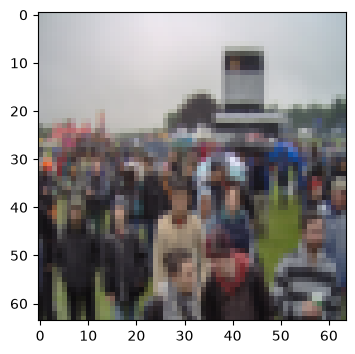

In [33]:
# Example of a picture
index = 100
plt.imshow(train_x_orig[index])
print ("y = " + str(train_y[0,index]) + ". It's a " + classes[train_y[0,index]].decode("utf-8") +  " picture.")

In [34]:
# Explore your dataset 
m_train = train_x_orig.shape[0]
num_px = train_x_orig.shape[1]
m_test = test_x_orig.shape[0]

print ("Number of training examples: " + str(m_train))
print ("Number of testing examples: " + str(m_test))
print ("Each image is of size: (" + str(num_px) + ", " + str(num_px) + ", 3)")
print ("train_x_orig shape: " + str(train_x_orig.shape))
print ("train_y shape: " + str(train_y.shape))
print ("test_x_orig shape: " + str(test_x_orig.shape))
print ("test_y shape: " + str(test_y.shape))

Number of training examples: 209
Number of testing examples: 50
Each image is of size: (64, 64, 3)
train_x_orig shape: (209, 64, 64, 3)
train_y shape: (1, 209)
test_x_orig shape: (50, 64, 64, 3)
test_y shape: (1, 50)


As usual, you reshape and standardize the images before feeding them to the network. The code is given in the cell below.

<img src="imvector2.png" style="width:450px;height:300px;">

<caption><center> <u>Figure 1</u>: Image to vector conversion. <br> </center></caption>

In [35]:
# Reshape the training and test examples 
train_x_flatten = train_x_orig.reshape(train_x_orig.shape[0], -1).T   # The "-1" makes reshape flatten the remaining dimensions
test_x_flatten = test_x_orig.reshape(test_x_orig.shape[0], -1).T

# Standardize data to have feature values between 0 and 1.
train_x = train_x_flatten/255.
test_x = test_x_flatten/255.

print ("train_x's shape: " + str(train_x.shape))
print ("test_x's shape: " + str(test_x.shape))


train_x's shape: (12288, 209)
test_x's shape: (12288, 50)


$12,288$ equals $64 \times 64 \times 3$ which is the size of one reshaped image vector.

## 3 - Architecture of your model

Now that you are familiar with the dataset, it is time to build a deep neural network to distinguish cat images from non-cat images.

You will build two different models:
- A 2-layer neural network
- An L-layer deep neural network

You will then compare the performance of these models, and also try out different values for $L$. 

Let's look at the two architectures.

### 3.1 - 2-layer neural network

<img src="2layerNN.png" style="width:650px;height:400px;">
<caption><center> <u>Figure 2</u>: 2-layer neural network. <br> The model can be summarized as: ***INPUT -> LINEAR -> RELU -> LINEAR -> SIGMOID -> OUTPUT***. </center></caption>

<u>Detailed Architecture of figure 2</u>:
- The input is a (64,64,3) image which is flattened to a vector of size $(12288,1)$. 
- The corresponding vector: $[x_0,x_1,...,x_{12287}]^T$ is then multiplied by the weight matrix $W^{[1]}$ of size $(n^{[1]}, 12288)$.
- You then add a bias term and take its relu to get the following vector: $[a_0^{[1]}, a_1^{[1]},..., a_{n^{[1]}-1}^{[1]}]^T$.
- You then repeat the same process.
- You multiply the resulting vector by $W^{[2]}$ and add your intercept (bias). 
- Finally, you take the sigmoid of the result. If it is greater than 0.5, you classify it to be a cat.

### 3.2 - L-layer deep neural network

It is hard to represent an L-layer deep neural network with the above representation. However, here is a simplified network representation:

<img src="LlayerNN.png" style="width:650px;height:400px;">
<caption><center> <u>Figure 3</u>: L-layer neural network. <br> The model can be summarized as: ***[LINEAR -> RELU] $\times$ (L-1) -> LINEAR -> SIGMOID***</center></caption>

<u>Detailed Architecture of figure 3</u>:
- The input is a (64,64,3) image which is flattened to a vector of size (12288,1).
- The corresponding vector: $[x_0,x_1,...,x_{12287}]^T$ is then multiplied by the weight matrix $W^{[1]}$ and then you add the intercept $b^{[1]}$. The result is called the linear unit.
- Next, you take the relu of the linear unit. 
- This process could be repeated several times for each $(W^{[l]}, b^{[l]})$ depending on the model architecture.
- Finally, you take the sigmoid of the final linear unit. If it is greater than 0.5, you classify it to be a cat.

### 3.3 - General methodology

As usual you will follow the Deep Learning methodology to build the model:
    1. Initialize parameters / Define hyperparameters
    2. Loop for num_iterations:
        a. Forward propagation
        b. Compute cost function
        c. Backward propagation
        d. Update parameters (using parameters, and grads from backprop) 
    4. Use trained parameters to predict labels

Let's now implement those two models!

## 4 - Two-layer neural network

**Question**:  Use the provided functions to build a 2-layer neural network with the following structure: *LINEAR -> RELU -> LINEAR -> SIGMOID*. The functions you may need and their inputs are:
```python
def initialize_parameters(n_x, n_h, n_y):
    ...
    return parameters 
def linear_activation_forward(A_prev, W, b, activation):
    ...
    return A, cache
def compute_cost(AL, Y):
    ...
    return cost
def linear_activation_backward(dA, cache, activation):
    ...
    return dA_prev, dW, db
def update_parameters(parameters, grads, learning_rate):
    ...
    return parameters
```

In [36]:
### CONSTANTS DEFINING THE MODEL ####
n_x = 12288     # num_px * num_px * 3
n_h = 7
n_y = 1
layers_dims = (n_x, n_h, n_y)

In [37]:
# two_layer_model

def two_layer_model(X, Y, layers_dims, learning_rate = 0.0075, num_iterations = 3000, print_cost=False):
    """
    Implements a two-layer neural network: LINEAR->RELU->LINEAR->SIGMOID.
    
    Arguments:
    X -- input data, of shape (n_x, number of examples)
    Y -- true "label" vector (containing 0 if cat, 1 if non-cat), of shape (1, number of examples)
    layers_dims -- dimensions of the layers (n_x, n_h, n_y)
    num_iterations -- number of iterations of the optimization loop
    learning_rate -- learning rate of the gradient descent update rule
    print_cost -- If set to True, this will print the cost every 100 iterations 
    
    Returns:
    parameters -- a dictionary containing W1, W2, b1, and b2
    """
    
    np.random.seed(1)
    grads = {}
    costs = []                              # to keep track of the cost
    m = X.shape[1]                           # number of examples
    (n_x, n_h, n_y) = layers_dims
    
    # Initialize parameters dictionary, by calling one of the provided functions
    parameters = initialize_parameters(n_x, n_h, n_y)
    
    # Get W1, b1, W2 and b2 from the dictionary parameters.
    W1 = parameters["W1"]
    b1 = parameters["b1"]
    W2 = parameters["W2"]
    b2 = parameters["b2"]
    
    # Loop (gradient descent)

    for i in range(0, num_iterations):

        # Forward propagation: LINEAR -> RELU -> LINEAR -> SIGMOID. Inputs: "X, W1, b1". Output: "A1, cache1, A2, cache2".
        A1, cache1 = linear_activation_forward(X, W1, b1, activation = "relu")
        A2, cache2 = linear_activation_forward(A1, W2, b2, activation = "sigmoid")
        
        # Compute cost
        cost = compute_cost(A2, Y)
        
        # Initializing backward propagation
        dA2 = - (np.divide(Y, A2) - np.divide(1 - Y, 1 - A2))
        
        # Backward propagation. Inputs: "dA2, cache2, cache1". Outputs: "dA1, dW2, db2; also dA0 (not used), dW1, db1".
        dA1, dW2, db2 = linear_activation_backward(dA2, cache2, activation = "sigmoid")
        dA0, dW1, db1 = linear_activation_backward(dA1, cache1, activation = "relu")
        
        # Set grads['dWl'] to dW1, grads['db1'] to db1, grads['dW2'] to dW2, grads['db2'] to db2
        grads['dW1'] = dW1
        grads['db1'] = db1
        grads['dW2'] = dW2
        grads['db2'] = db2
        
        # Update parameters.
        parameters = update_parameters(parameters, grads, learning_rate)

        # Retrieve W1, b1, W2, b2 from parameters
        W1 = parameters["W1"]
        b1 = parameters["b1"]
        W2 = parameters["W2"]
        b2 = parameters["b2"]
        
        # Print the cost every 100 training example
        if print_cost and i % 100 == 0:
            print("Cost after iteration {}: {}".format(i, np.squeeze(cost)))
        if print_cost and i % 100 == 0:
            costs.append(cost)
       
    # plot the cost

    plt.plot(np.squeeze(costs))
    plt.ylabel('cost')
    plt.xlabel('iterations (per tens)')
    plt.title("Learning rate =" + str(learning_rate))
    plt.show()
    
    return parameters

### Action
Run the cell below to train your parameters. See if your model runs. The cost should be decreasing. It may take up to 5 minutes to run 2500 iterations. 

Check if the "Cost after iteration 0" is equal to "0.69304...", if not click on the square (⬛) on the upper bar of the notebook to stop the cell and try to find your error.

Cost after iteration 0: 0.693049735659989
Cost after iteration 100: 0.6464320953428849
Cost after iteration 200: 0.6325140647912678
Cost after iteration 300: 0.6015024920354665
Cost after iteration 400: 0.5601966311605747
Cost after iteration 500: 0.5158304772764729
Cost after iteration 600: 0.4754901313943325
Cost after iteration 700: 0.4339163151225749
Cost after iteration 800: 0.40079775362038866
Cost after iteration 900: 0.35807050113237987
Cost after iteration 1000: 0.3394281538366413
Cost after iteration 1100: 0.3052753636196264
Cost after iteration 1200: 0.2749137728213015
Cost after iteration 1300: 0.24681768210614818
Cost after iteration 1400: 0.19850735037466102
Cost after iteration 1500: 0.1744831811255664
Cost after iteration 1600: 0.1708076297809689
Cost after iteration 1700: 0.11306524562164712
Cost after iteration 1800: 0.09629426845937156
Cost after iteration 1900: 0.08342617959726865
Cost after iteration 2000: 0.07439078704319085
Cost after iteration 2100: 0.0663074813

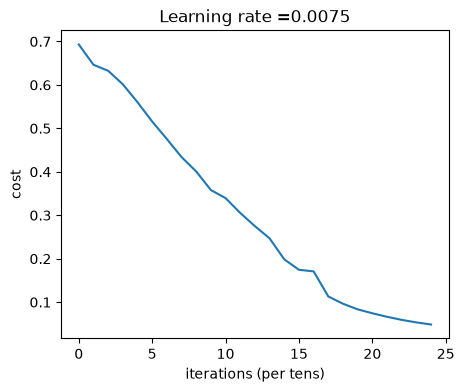

In [38]:
parameters = two_layer_model(train_x, train_y, layers_dims = (n_x, n_h, n_y), num_iterations = 2500, print_cost=True)

**Expected Output**:
<table> 
    <tr>
        <td> **Cost after iteration 0**</td>
        <td> 0.6930497356599888 </td>
    </tr>
    <tr>
        <td> **Cost after iteration 100**</td>
        <td> 0.6464320953428849 </td>
    </tr>
    <tr>
        <td> **...**</td>
        <td> ... </td>
    </tr>
    <tr>
        <td> **Cost after iteration 2400**</td>
        <td> 0.048554785628770206 </td>
    </tr>
</table>

### Action

Now, you can use the trained parameters to classify images from the dataset. To see your predictions on the training and test sets, run the cell below.

In [39]:
predictions_train = predict(train_x, train_y, parameters)

Accuracy: 0.9999999999999998


**Expected Output**:
<table> 
    <tr>
        <td> **Accuracy**</td>
        <td> 1.0 </td>
    </tr>
</table>

In [40]:
predictions_test = predict(test_x, test_y, parameters)

Accuracy: 0.72


**Expected Output**:

<table> 
    <tr>
        <td> **Accuracy**</td>
        <td> 0.72 </td>
    </tr>
</table>

## TO DO1:

- Run the model several times with the following values of the learning rate parameter: 0.75 and 0.075. 
- Analyse the results.

--- Training with learning rate = 0.75 ---
Cost after iteration 0: 0.693049735659989
Cost after iteration 100: 0.6439737380530687
Cost after iteration 200: 0.6439737380528057
Cost after iteration 300: 0.6439737380528059
Cost after iteration 400: 0.6439737380528059
Cost after iteration 500: 0.6439737380528059
Cost after iteration 600: 0.6439737380528059
Cost after iteration 700: 0.6439737380528059
Cost after iteration 800: 0.6439737380528059
Cost after iteration 900: 0.6439737380528059
Cost after iteration 1000: 0.6439737380528059
Cost after iteration 1100: 0.6439737380528059
Cost after iteration 1200: 0.6439737380528059
Cost after iteration 1300: 0.6439737380528059
Cost after iteration 1400: 0.6439737380528059


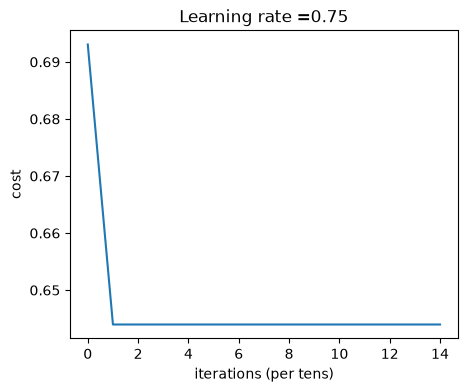


--- Training with learning rate = 0.075 ---
Cost after iteration 0: 0.693049735659989
Cost after iteration 100: 0.6159811750972888
Cost after iteration 200: 0.6008384836529501
Cost after iteration 300: 0.4101457640502173
Cost after iteration 400: 0.41302653655998894
Cost after iteration 500: 0.6559708062468972
Cost after iteration 600: 0.38563516055405606
Cost after iteration 700: 0.2686579033161089
Cost after iteration 800: 0.2782066868964342
Cost after iteration 900: 0.2792825930534414
Cost after iteration 1000: 0.2000892920891355
Cost after iteration 1100: 0.1781823039834751
Cost after iteration 1200: 0.988374620086969
Cost after iteration 1300: 0.6072691444543614
Cost after iteration 1400: 0.23016057610012589


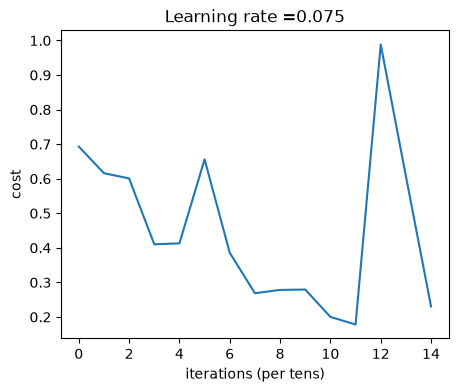

In [41]:
# TO DO 1: Testing different learning rates
print("--- Training with learning rate = 0.75 ---")
parameters_lr1 = two_layer_model(train_x, train_y, layers_dims = (n_x, n_h, n_y), learning_rate = 0.75, num_iterations = 1500, print_cost=True)

print("\n--- Training with learning rate = 0.075 ---")
parameters_lr2 = two_layer_model(train_x, train_y, layers_dims = (n_x, n_h, n_y), learning_rate = 0.075, num_iterations = 1500, print_cost=True)

## TO DO2:

- Run the model several times with different numbers of iterations and report the performance here. 
- Analyse the results.


--- Training with 500 iterations ---


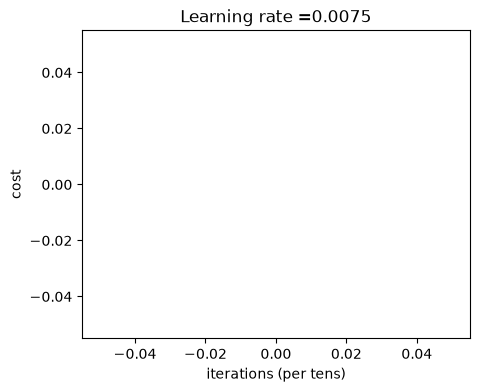

Accuracy: 0.6555023923444976
Accuracy: 0.3400000000000001
Iterations: 500 | Train Accuracy: 65.55% | Test Accuracy: 34.00%

--- Training with 1000 iterations ---


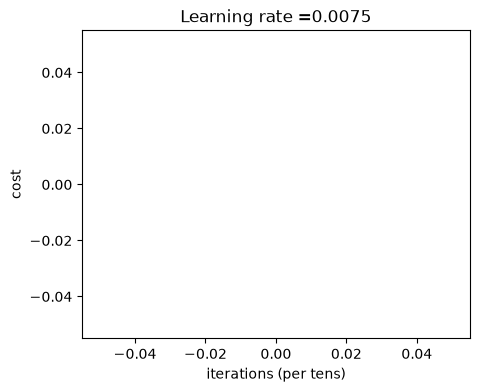

Accuracy: 0.8373205741626794
Accuracy: 0.5800000000000001
Iterations: 1000 | Train Accuracy: 83.73% | Test Accuracy: 58.00%


In [43]:
# TO DO 2: Testing different numbers of iterations
iterations_list = [500, 1000]

for iters in iterations_list:
    print(f"\n--- Training with {iters} iterations ---")
    parameters_it = two_layer_model(train_x, train_y, layers_dims = (n_x, n_h, n_y), learning_rate = 0.0075, num_iterations = iters, print_cost=False)
    
    train_acc = predict(train_x, train_y, parameters_it)
    test_acc = predict(test_x, test_y, parameters_it)
    train_accuracy = np.mean(train_acc == train_y)
    test_accuracy = np.mean(test_acc == test_y)
    print(f"Iterations: {iters} | Train Accuracy: {train_accuracy * 100:.2f}% | "
          f"Test Accuracy: {test_accuracy * 100:.2f}%")

## 5 - L-layer Neural Network

**Question**: Use the provided functions to build an $L$-layer neural network with the following structure: *[LINEAR -> RELU]$\times$(L-1) -> LINEAR -> SIGMOID*. 

The functions you may need and their inputs are:
```python
def initialize_parameters_deep(layer_dims):
    ...
    return parameters 
def L_model_forward(X, parameters):
    ...
    return AL, caches
def compute_cost(AL, Y):
    ...
    return cost
def L_model_backward(AL, Y, caches):
    ...
    return grads
def update_parameters(parameters, grads, learning_rate):
    ...
    return parameters
```

In [44]:
### CONSTANTS ###
#  5-layer model You cannot change the number of layers, 
# but you can change the number of neurons per layer

layers_dims = [12288, 20, 7, 5, 1] 

In [45]:
def L_layer_model(X, Y, layers_dims, learning_rate = 0.0075, num_iterations = 3000, print_cost=False):
    """
    Implements a L-layer neural network: [LINEAR->RELU]*(L-1)->LINEAR->SIGMOID.
    """
    np.random.seed(1)
    costs = []                         # keep track of cost
    
    # Parameters initialization.
    parameters = initialize_parameters_deep(layers_dims)
    
    # Loop (gradient descent)
    for i in range(0, num_iterations):

        # Forward propagation
        AL, caches = L_model_forward(X, parameters)
        
        # Compute cost
        cost = compute_cost(AL, Y)
    
        # Backward propagation
        grads = L_model_backward(AL, Y, caches)
 
        # Update parameters
        parameters = update_parameters(parameters, grads, learning_rate)
                
        # RECORD COST EVERY 100 ITERATIONS UNCONDITIONALLY
        if i % 100 == 0:
            if print_cost:
                print ("Cost after iteration %i: %f" %(i, cost))
            costs.append(np.squeeze(cost))
            
    # Plot the cost correctly
    plt.figure()
    plt.plot(costs)
    plt.ylabel('cost')
    plt.xlabel('iterations (per tens)')
    plt.title("Learning rate =" + str(learning_rate))
    plt.show()
    
    return parameters

You will now train the model as a 5-layer neural network. 

Run the cell below to train your model. The cost should decrease on every iteration. It may take up to 5 minutes to run 2500 iterations. Check if the "Cost after iteration 0" equals to "0.771749", if not click on the square (⬛) on the upper bar of the notebook to stop the cell and try to find your error.

Cost after iteration 0: 0.771749
Cost after iteration 100: 0.672053
Cost after iteration 200: 0.648263
Cost after iteration 300: 0.611507
Cost after iteration 400: 0.567047
Cost after iteration 500: 0.540138
Cost after iteration 600: 0.527930
Cost after iteration 700: 0.465477
Cost after iteration 800: 0.369126
Cost after iteration 900: 0.391747
Cost after iteration 1000: 0.315187
Cost after iteration 1100: 0.272700
Cost after iteration 1200: 0.237419
Cost after iteration 1300: 0.199601
Cost after iteration 1400: 0.189263
Cost after iteration 1500: 0.161189
Cost after iteration 1600: 0.148214
Cost after iteration 1700: 0.137775
Cost after iteration 1800: 0.129740
Cost after iteration 1900: 0.121225
Cost after iteration 2000: 0.113821
Cost after iteration 2100: 0.107839
Cost after iteration 2200: 0.102855
Cost after iteration 2300: 0.100897
Cost after iteration 2400: 0.092878


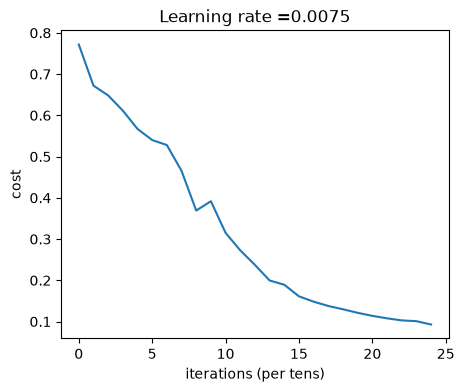

In [46]:
parameters = L_layer_model(train_x, train_y, layers_dims, num_iterations = 2500, print_cost = True)

**Expected Output**:
<table> 
    <tr>
        <td> **Cost after iteration 0**</td>
        <td> 0.771749 </td>
    </tr>
    <tr>
        <td> **Cost after iteration 100**</td>
        <td> 0.672053 </td>
    </tr>
    <tr>
        <td> **...**</td>
        <td> ... </td>
    </tr>
    <tr>
        <td> **Cost after iteration 2400**</td>
        <td> 0.092878 </td>
    </tr>
</table>

In [47]:
pred_train = predict(train_x, train_y, parameters)

Accuracy: 0.9856459330143539


<table>
    <tr>
    <td>
    **Train Accuracy**
    </td>
    <td>
    0.985645933014
    </td>
    </tr>
</table>

In [48]:
pred_test = predict(test_x, test_y, parameters)

Accuracy: 0.8


**Expected Output**:

<table> 
    <tr>
        <td> **Test Accuracy**</td>
        <td> 0.8 </td>
    </tr>
</table>

It seems that your 5-layer neural network has better performance (80%) than your 2-layer neural network (72%) on the same test set. 

This is good performance for this task. Nice job! 

Though we can obtained better results using what you will learn later in this course...

##  6) Results Analysis

First, let's take a look at some images the L-layer model labeled incorrectly. This will show a few mislabeled images. 

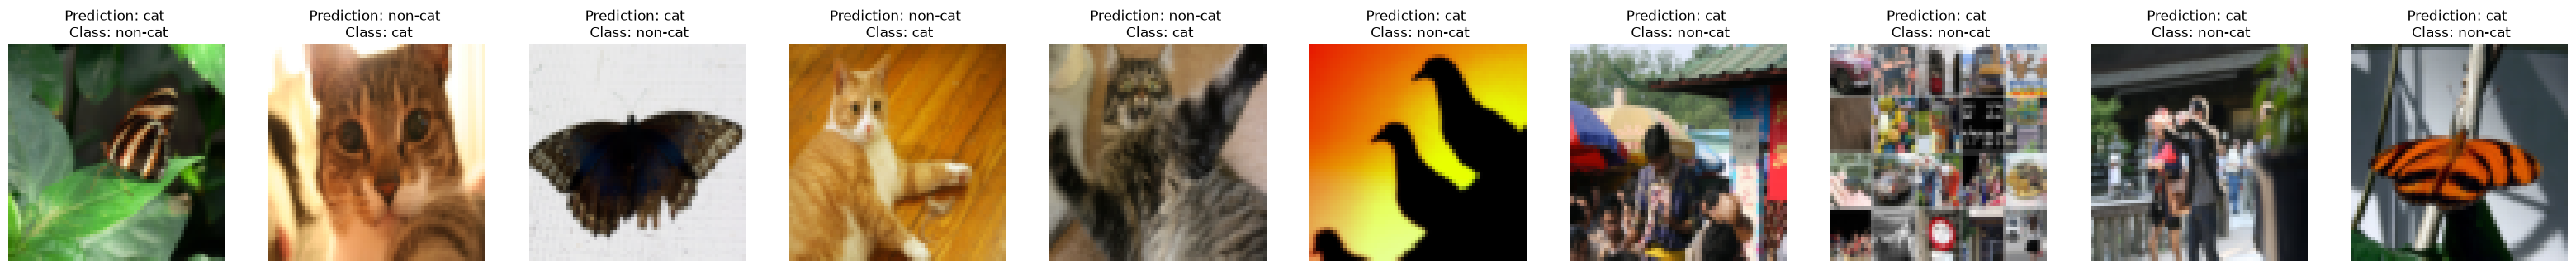

In [49]:
print_mislabeled_images(classes, test_x, test_y, pred_test)

**A few type of images the model tends to do poorly on include:** 
- Cat body in an unusual position
- Cat appears against a background of a similar color
- Unusual cat color and species
- Camera Angle
- Brightness of the picture
- Scale variation (cat is very large or small in image) 

## 7) Test with your own image 

You can use your own image and see the output of your model. To do that:
    1. Click on "File" in the upper bar of this notebook, then click "Open" to go on your Coursera Hub.
    2. Add your image to this Jupyter Notebook's directory, in the "images" folder
    3. Change your image's name in the following code
    4. Run the code and check if the algorithm is right (1 = cat, 0 = non-cat)!

Accuracy: 1.0
y = 1.0, your L-layer model predicts a "cat" picture.


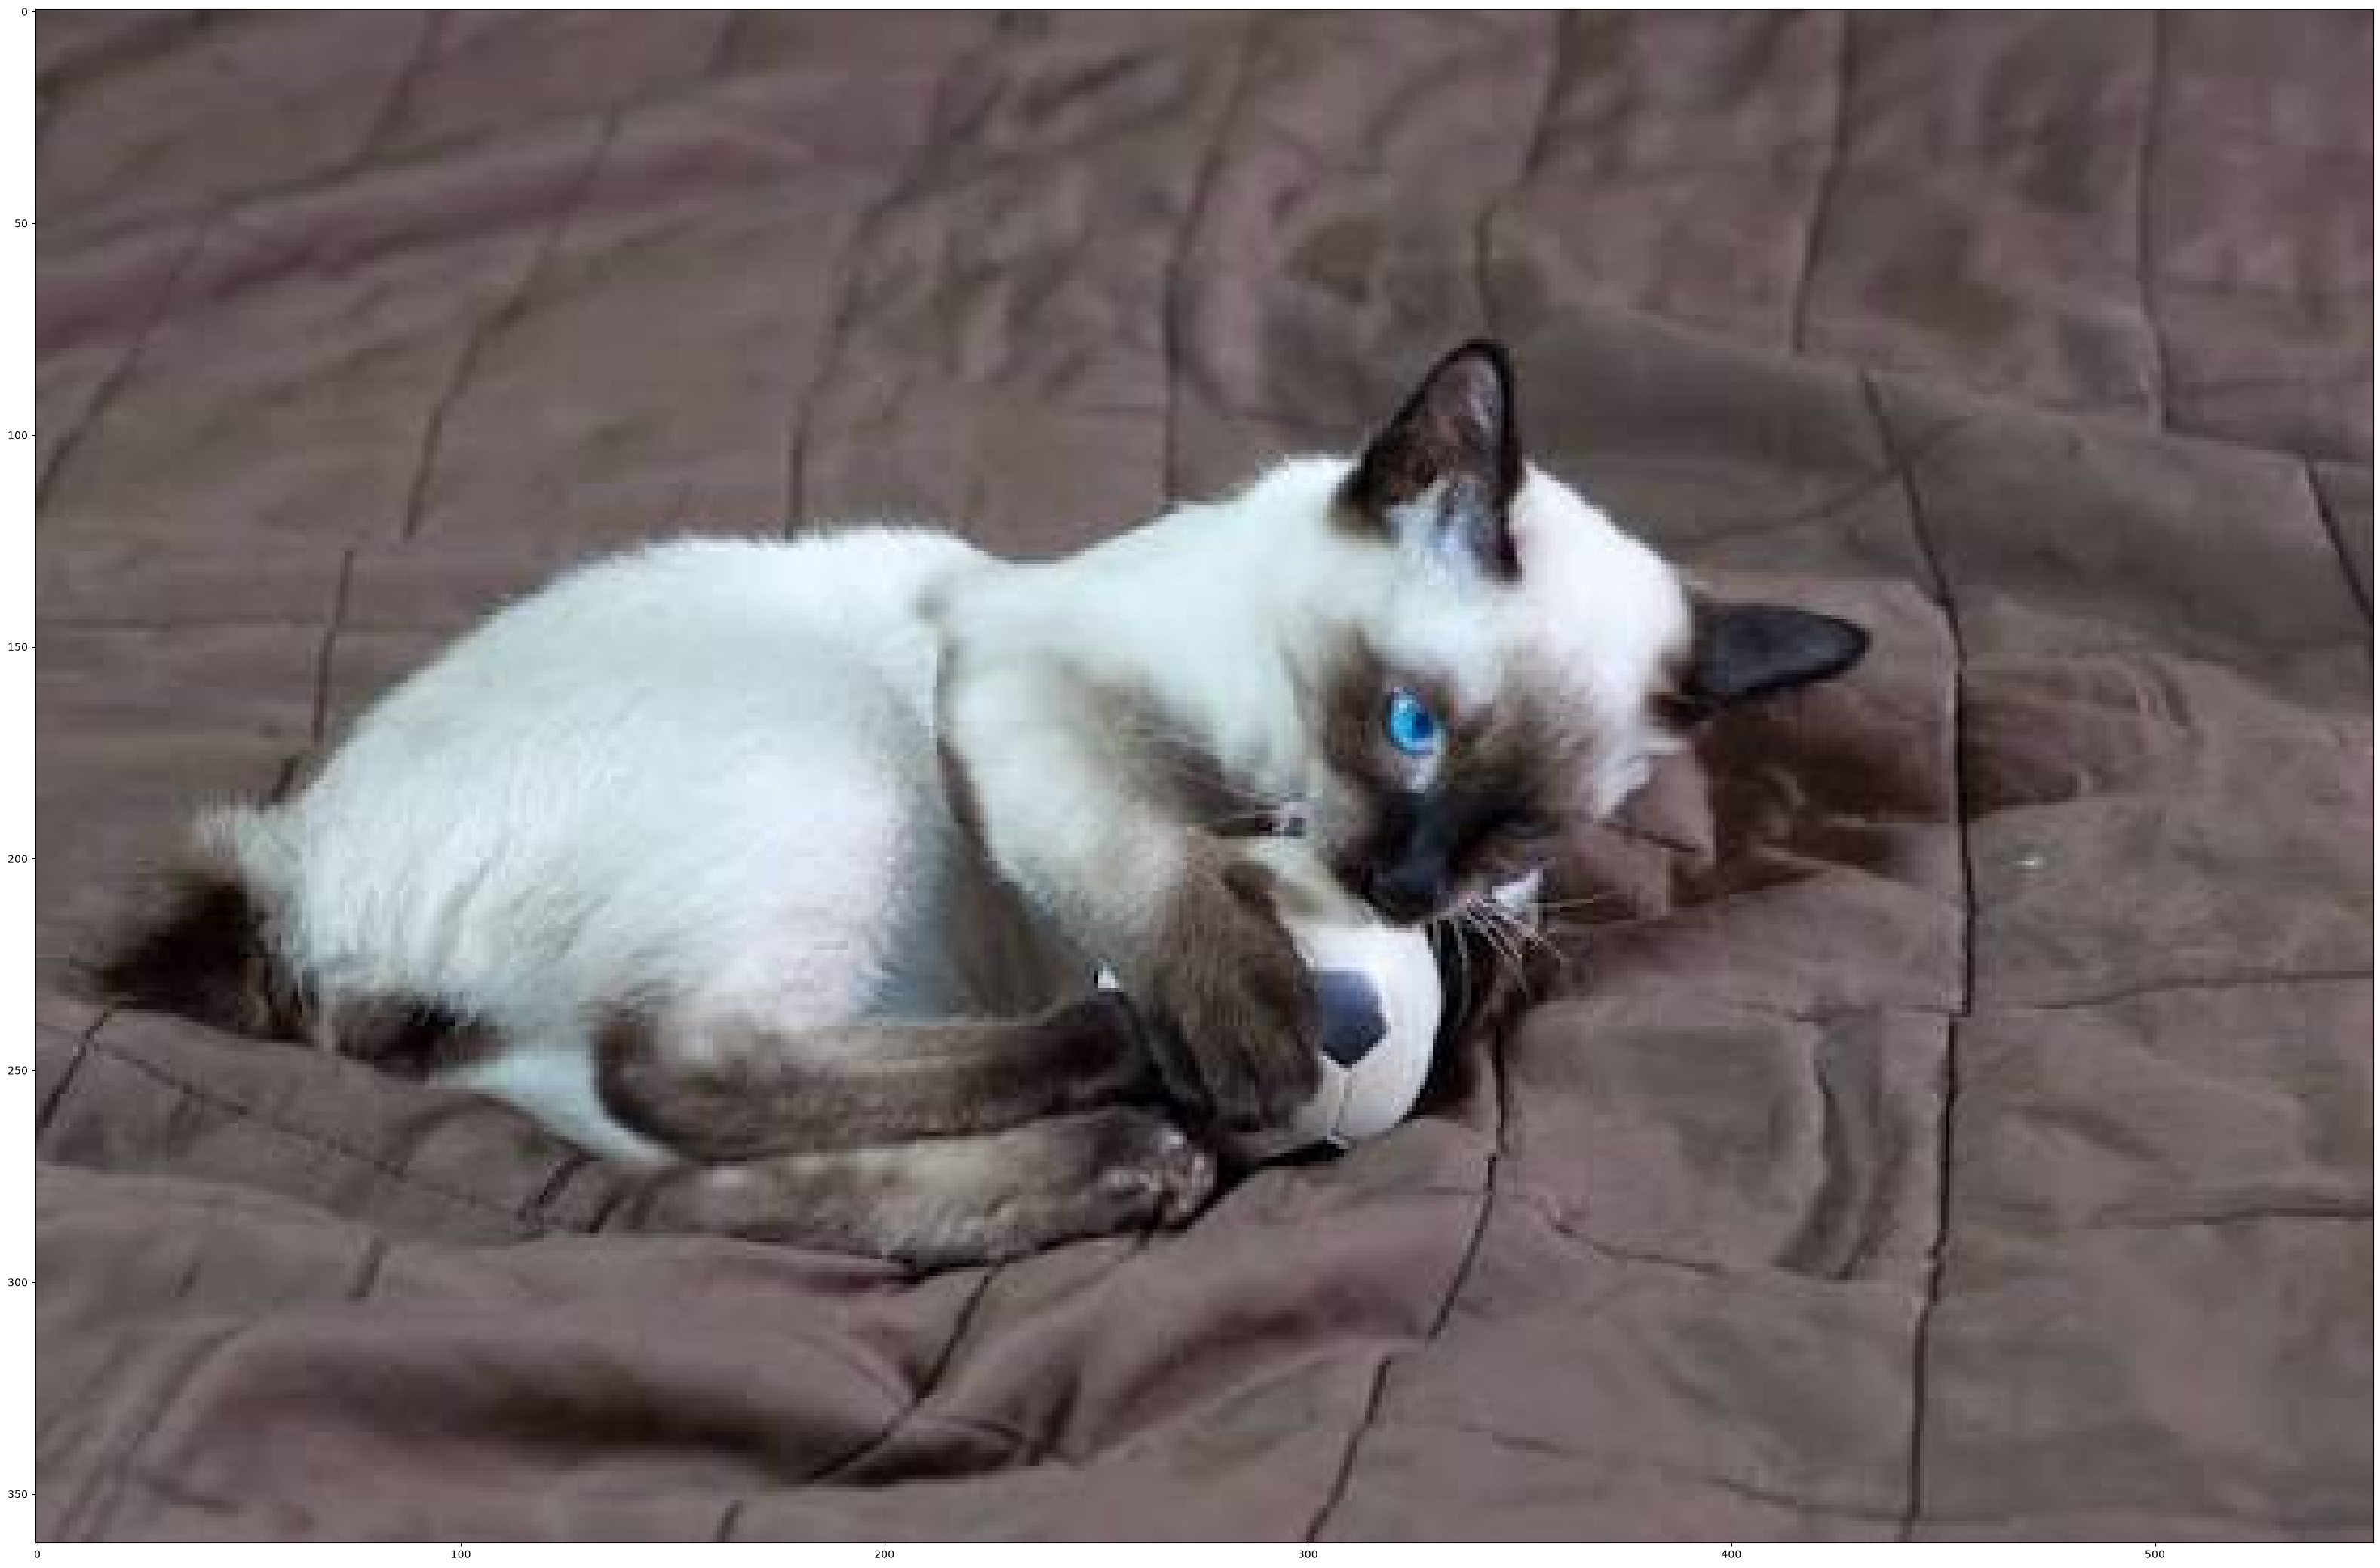

In [50]:
## START CODE HERE ##
fname = "images.jpeg" # change this to the name of your image file 
my_label_y = [1] # the true class of your image (1 -> cat, 0 -> non-cat)
## END CODE HERE ##

#fname = "images/" + my_image
image = imread(fname)
my_image = np.array(resize(image, (num_px, num_px))).reshape((num_px*num_px*3,1))

my_predicted_image = predict(my_image, my_label_y, parameters)

plt.imshow(image)
print ("y = " + str(np.squeeze(my_predicted_image)) + ", your L-layer model predicts a \"" + classes[int(np.squeeze(my_predicted_image)),].decode("utf-8") +  "\" picture.")

##  7) Tuning Neural Network Parameters

As you may know now, there a lot of parameters that can be tuned in order to increase the effectivness of the network and the speed of training (e.g. number of layers, learning rate...).

These Parameters can either modify the architecture of the NN or the training procedure. Each "run" with a specific set of parameters will generate specific results. 

### Work to do:
- Identify key parameters to change.
- For each instance of parameters, execute the training and the prediction and report the obtained results.
- Summarize the obtained results in a Table: You have to try at least 5 different sets of parameters.
- Analyze the obtained results

Your feed back on the work to do has to be written here...

- Number of layers
- Number of neurons in each layer.
- Learning rate
- Activation functions
- Number of learning iterations



Reference:
- Andrew NG labs.
- http://scs.ryerson.ca/~aharley/neural-networks/
- http://cs231n.github.io/neural-networks-case-study/

In [ ]:
experiments = [
    {
        "name": "1. Baseline (ReLU)", 
        "dims": [12288, 20, 7, 5, 1], 
        "lr": 0.0075, 
        "iters": 2500,
        "activation": "relu"
    },
    {
        "name": "2. Tanh Activation", 
        "dims": [12288, 20, 7, 5, 1], 
        "lr": 0.0075, 
        "iters": 2500,
        "activation": "tanh"
    },
    {
        "name": "3. Wider Network (ReLU)", 
        "dims": [12288, 64, 32, 16, 1], 
        "lr": 0.0075, 
        "iters": 2500,
        "activation": "relu"
    },
    {
        "name": "4. Extended Iterations (ReLU)", 
        "dims": [12288, 20, 7, 5, 1], 
        "lr": 0.0075, 
        "iters": 5000,
        "activation": "relu"
    },
    {
        "name": "5. Deeper Network (ReLU)", 
        "dims": [12288, 30, 20, 10, 5, 1], 
        "lr": 0.0075, 
        "iters": 2500,
        "activation": "relu"
    }
]



================ Running: 1. Baseline (ReLU) ================


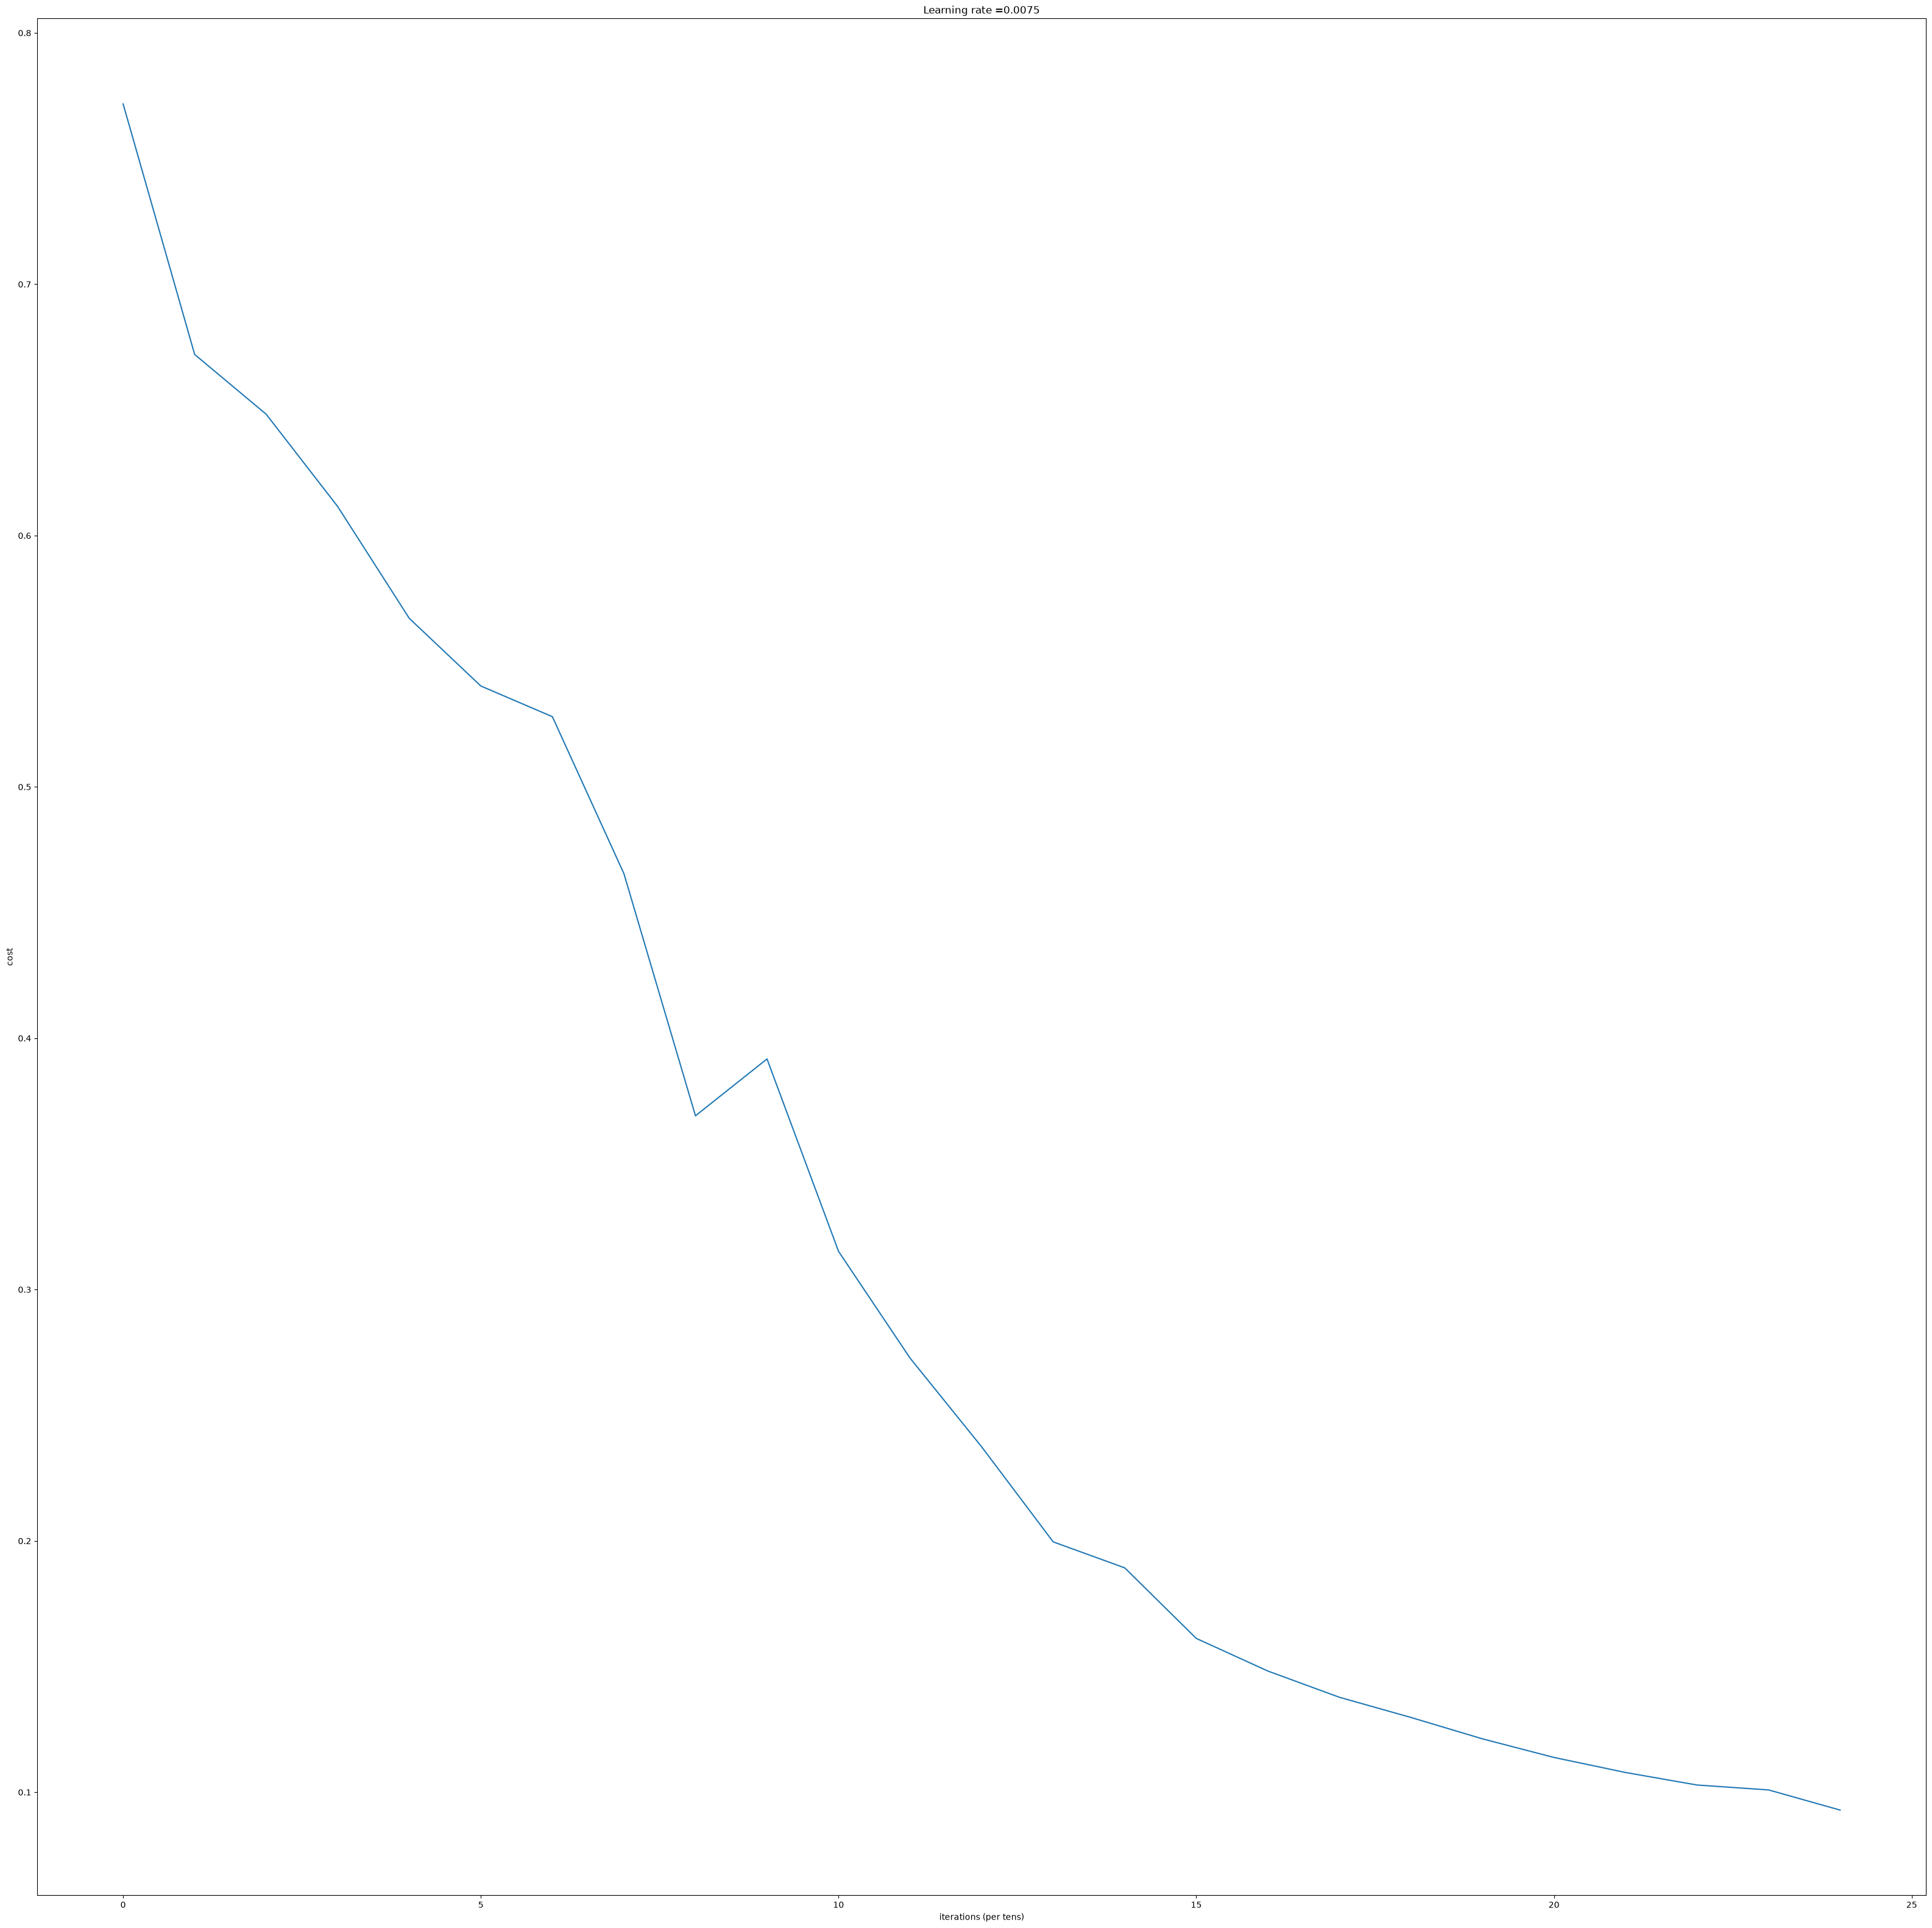

Accuracy: 0.9856459330143539
Accuracy: 0.8

================ Running: 2. Tanh Activation ================


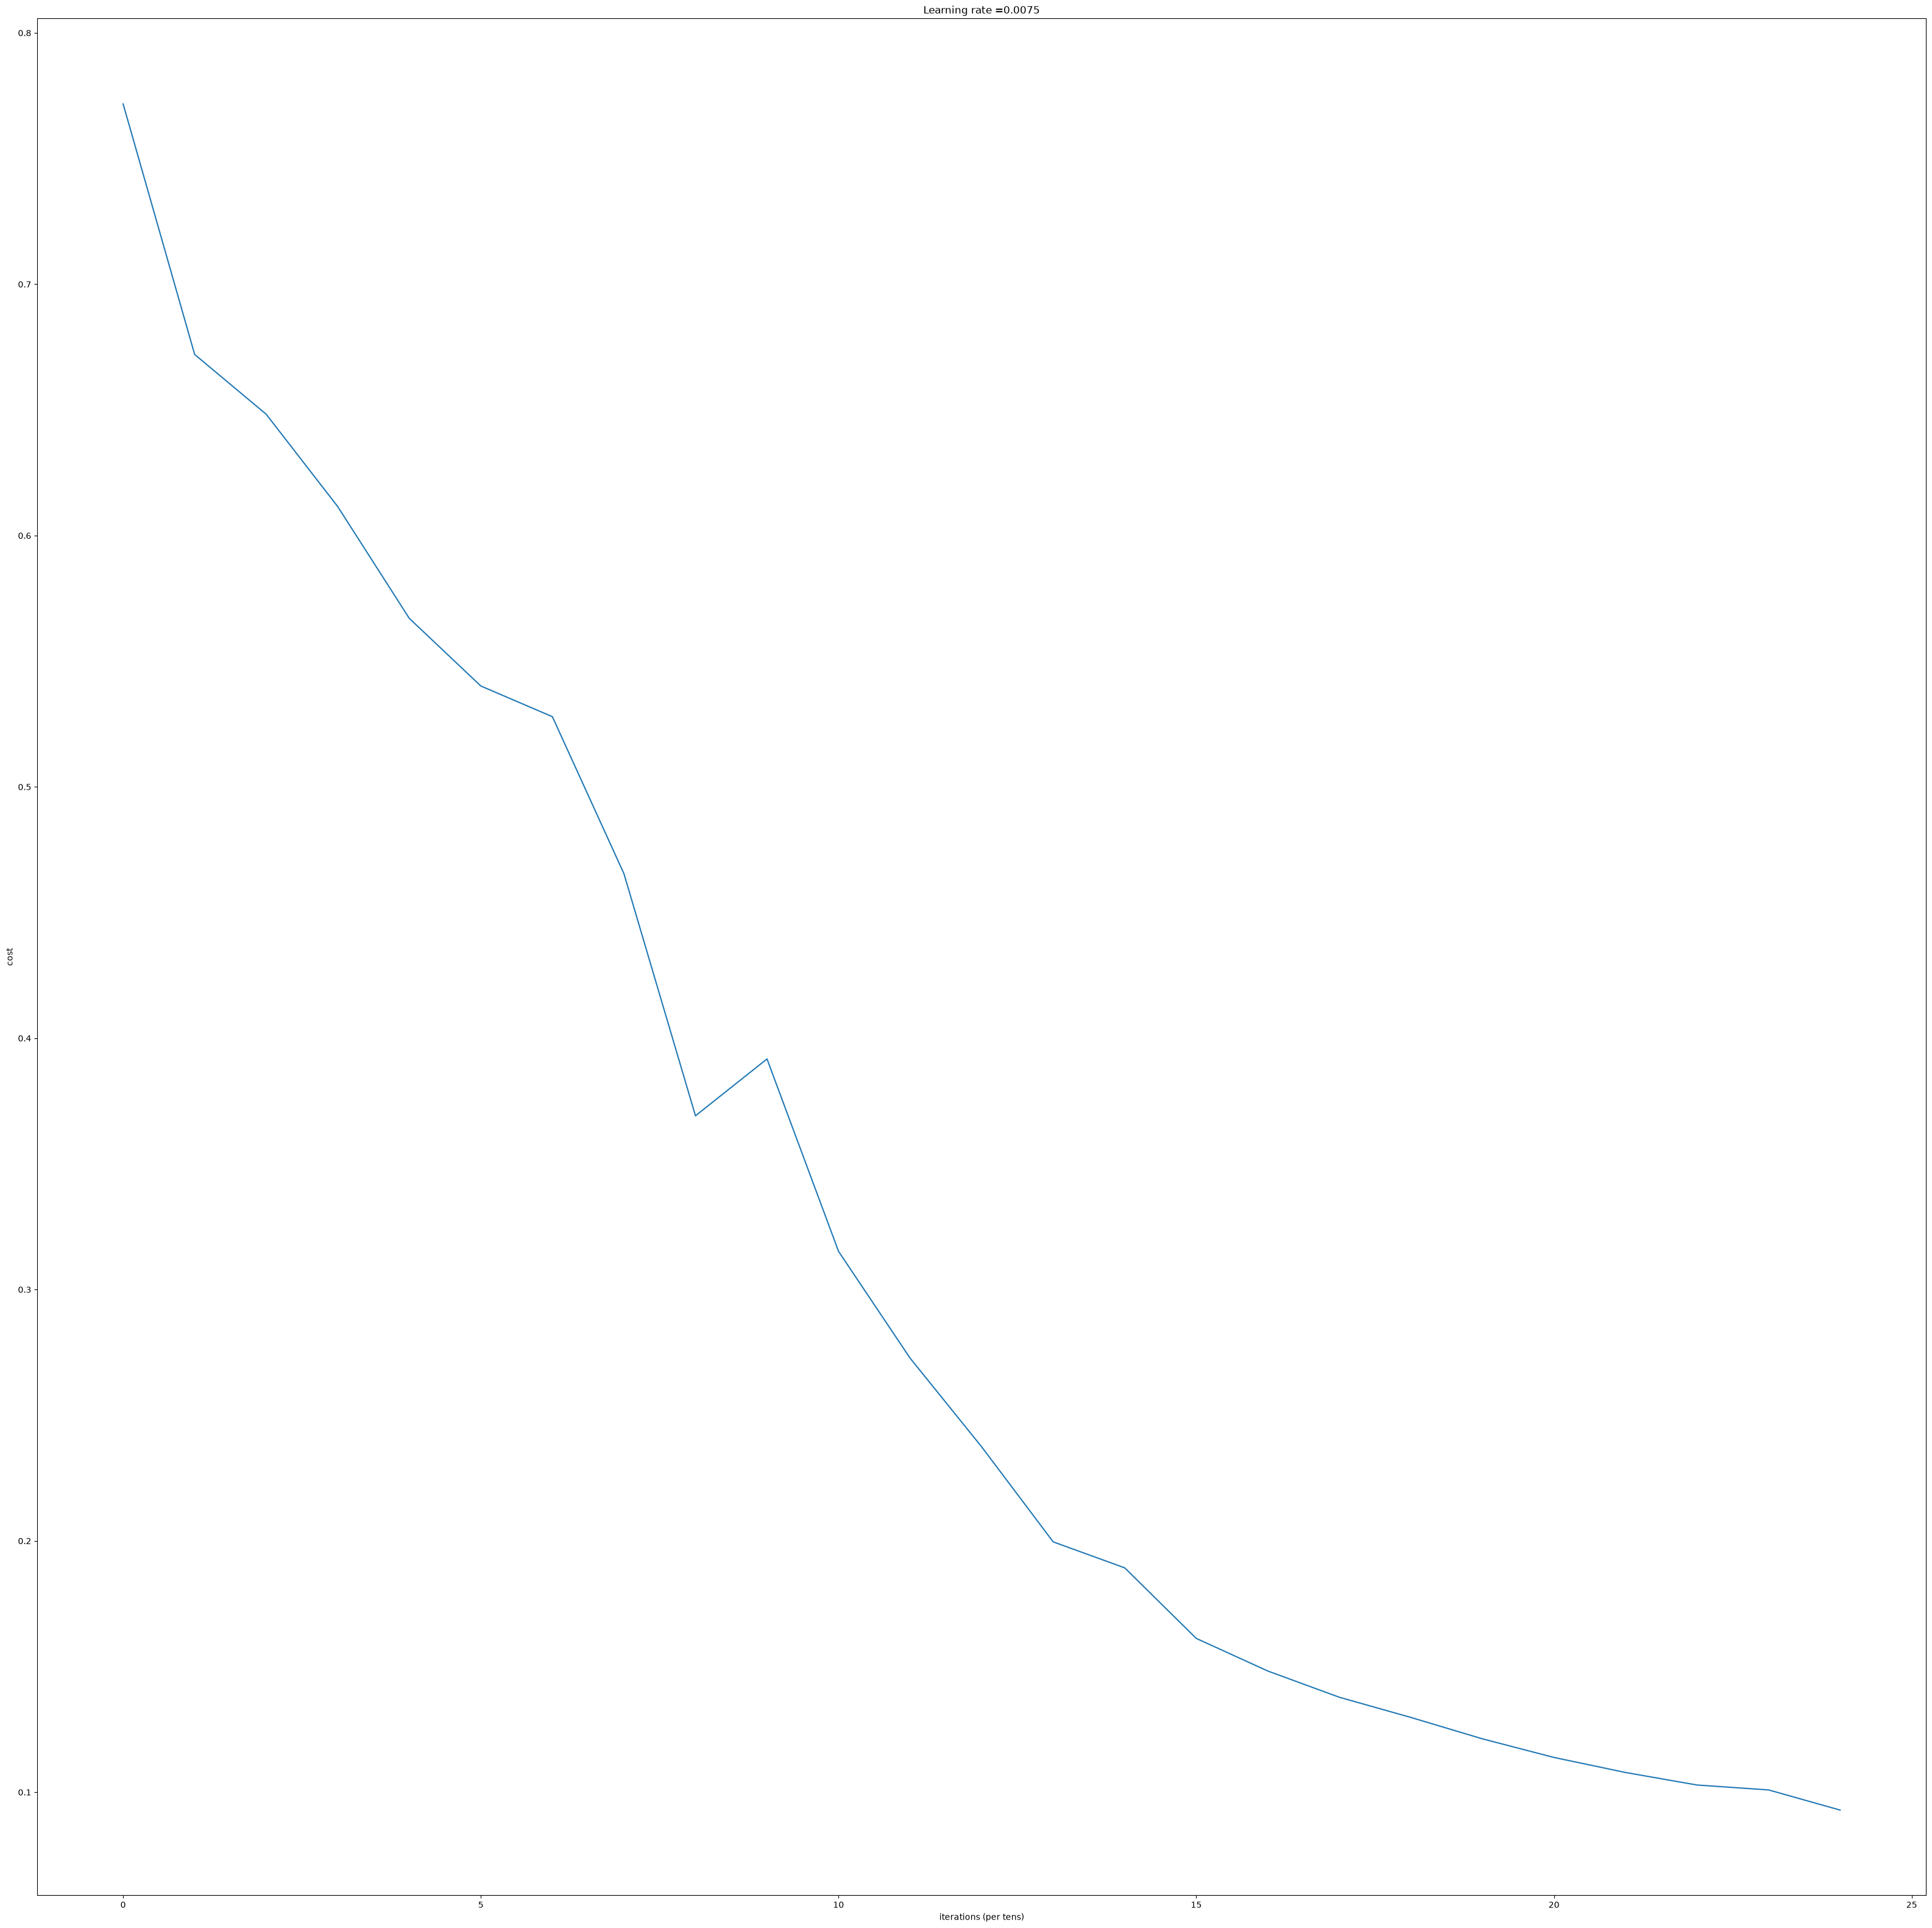

Accuracy: 0.9856459330143539
Accuracy: 0.8

================ Running: 3. Wider Network (ReLU) ================


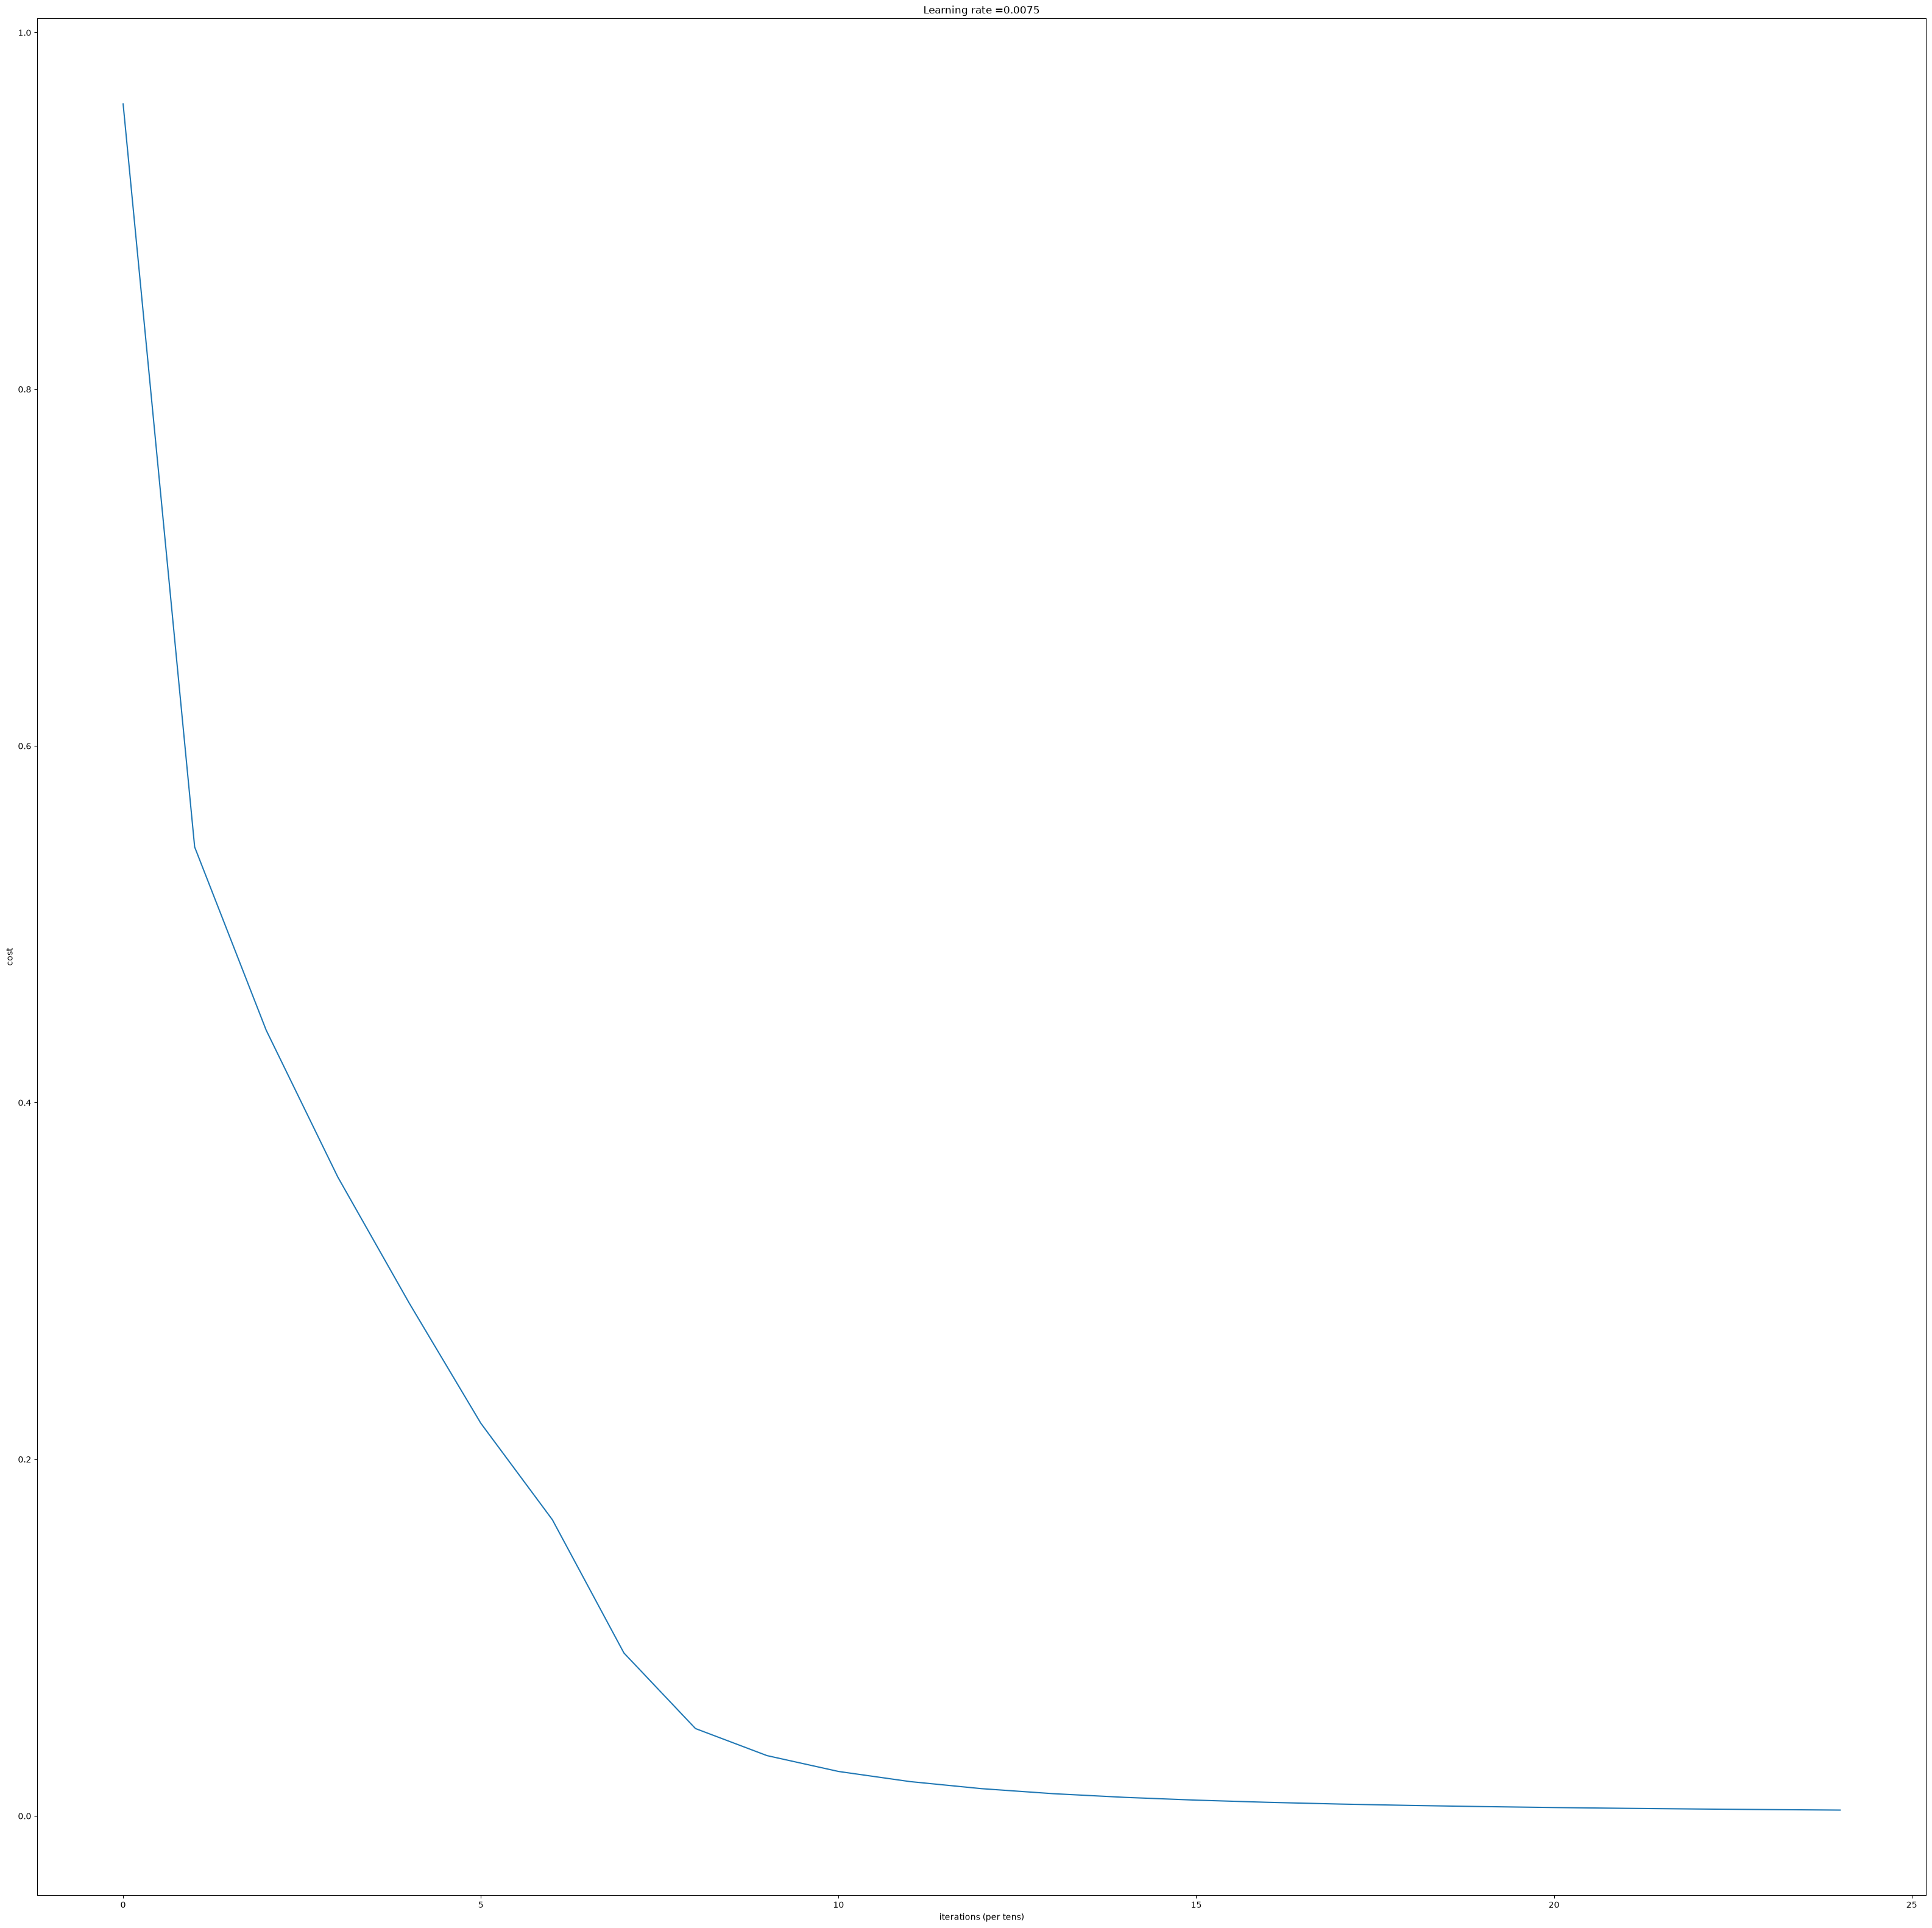

Accuracy: 0.9999999999999998
Accuracy: 0.8200000000000001

================ Running: 4. Extended Iterations (ReLU) ================


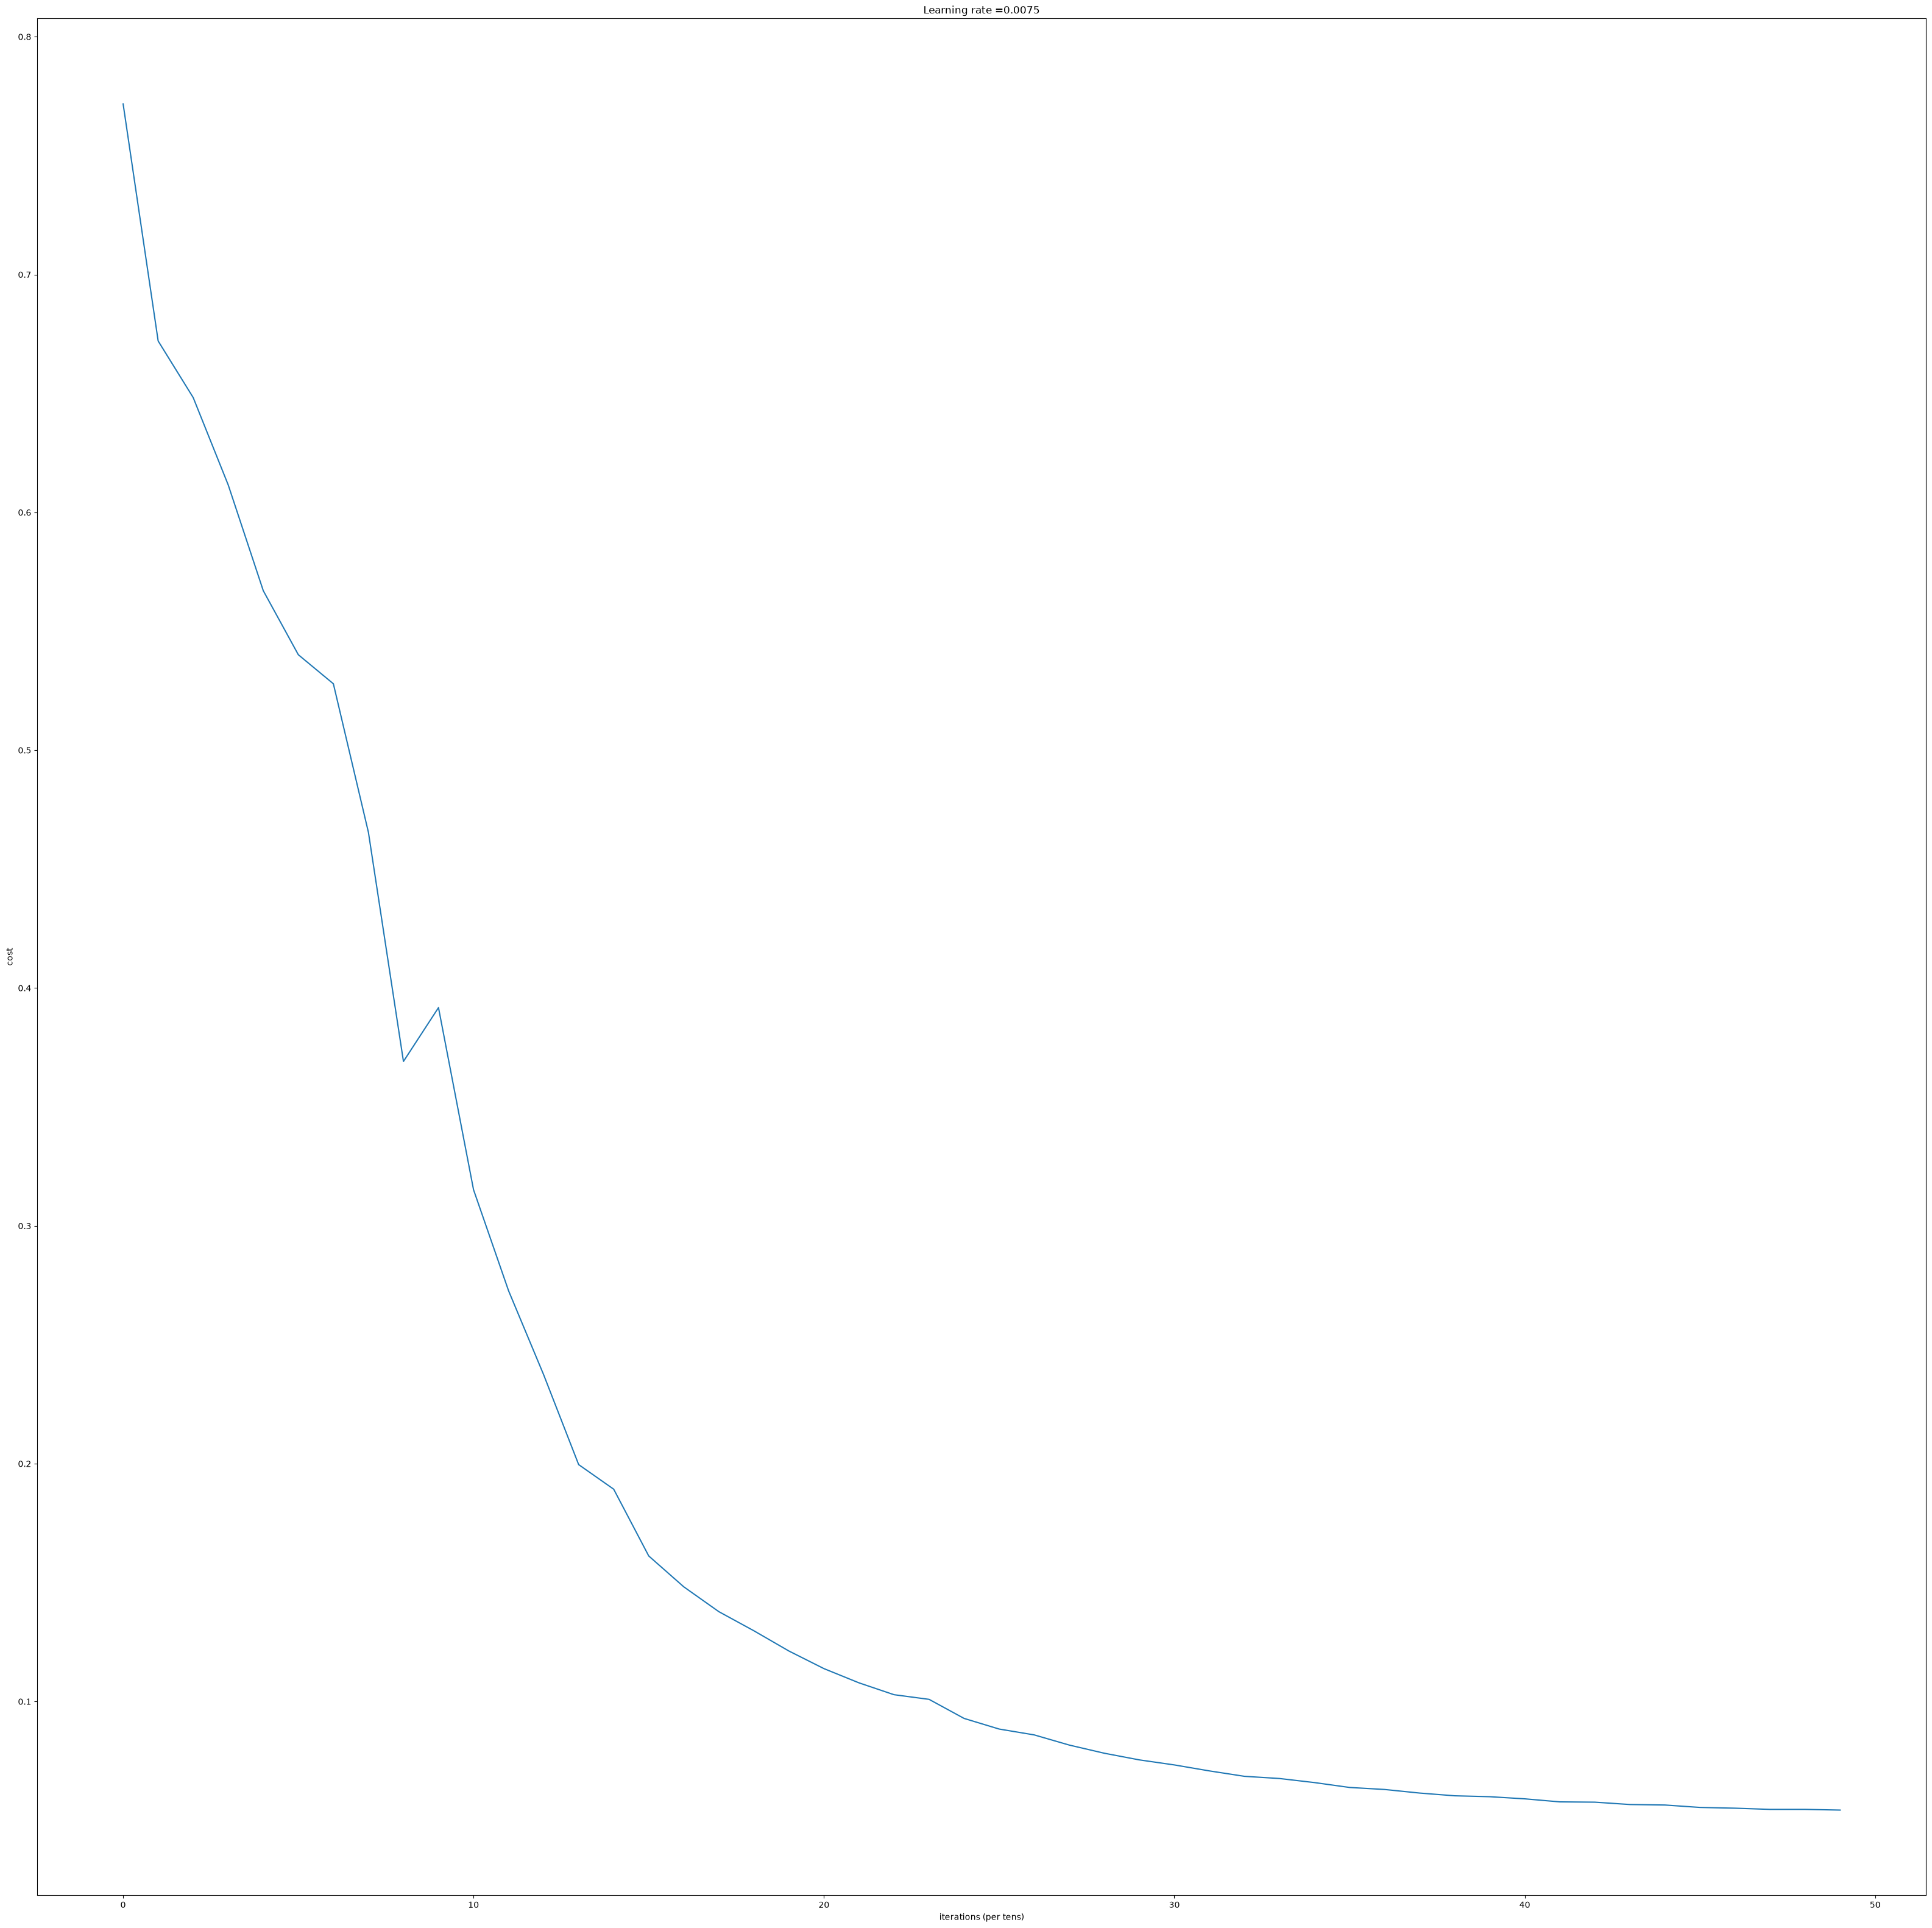

Accuracy: 0.9904306220095691
Accuracy: 0.78

================ Running: 5. Deeper Network (ReLU) ================


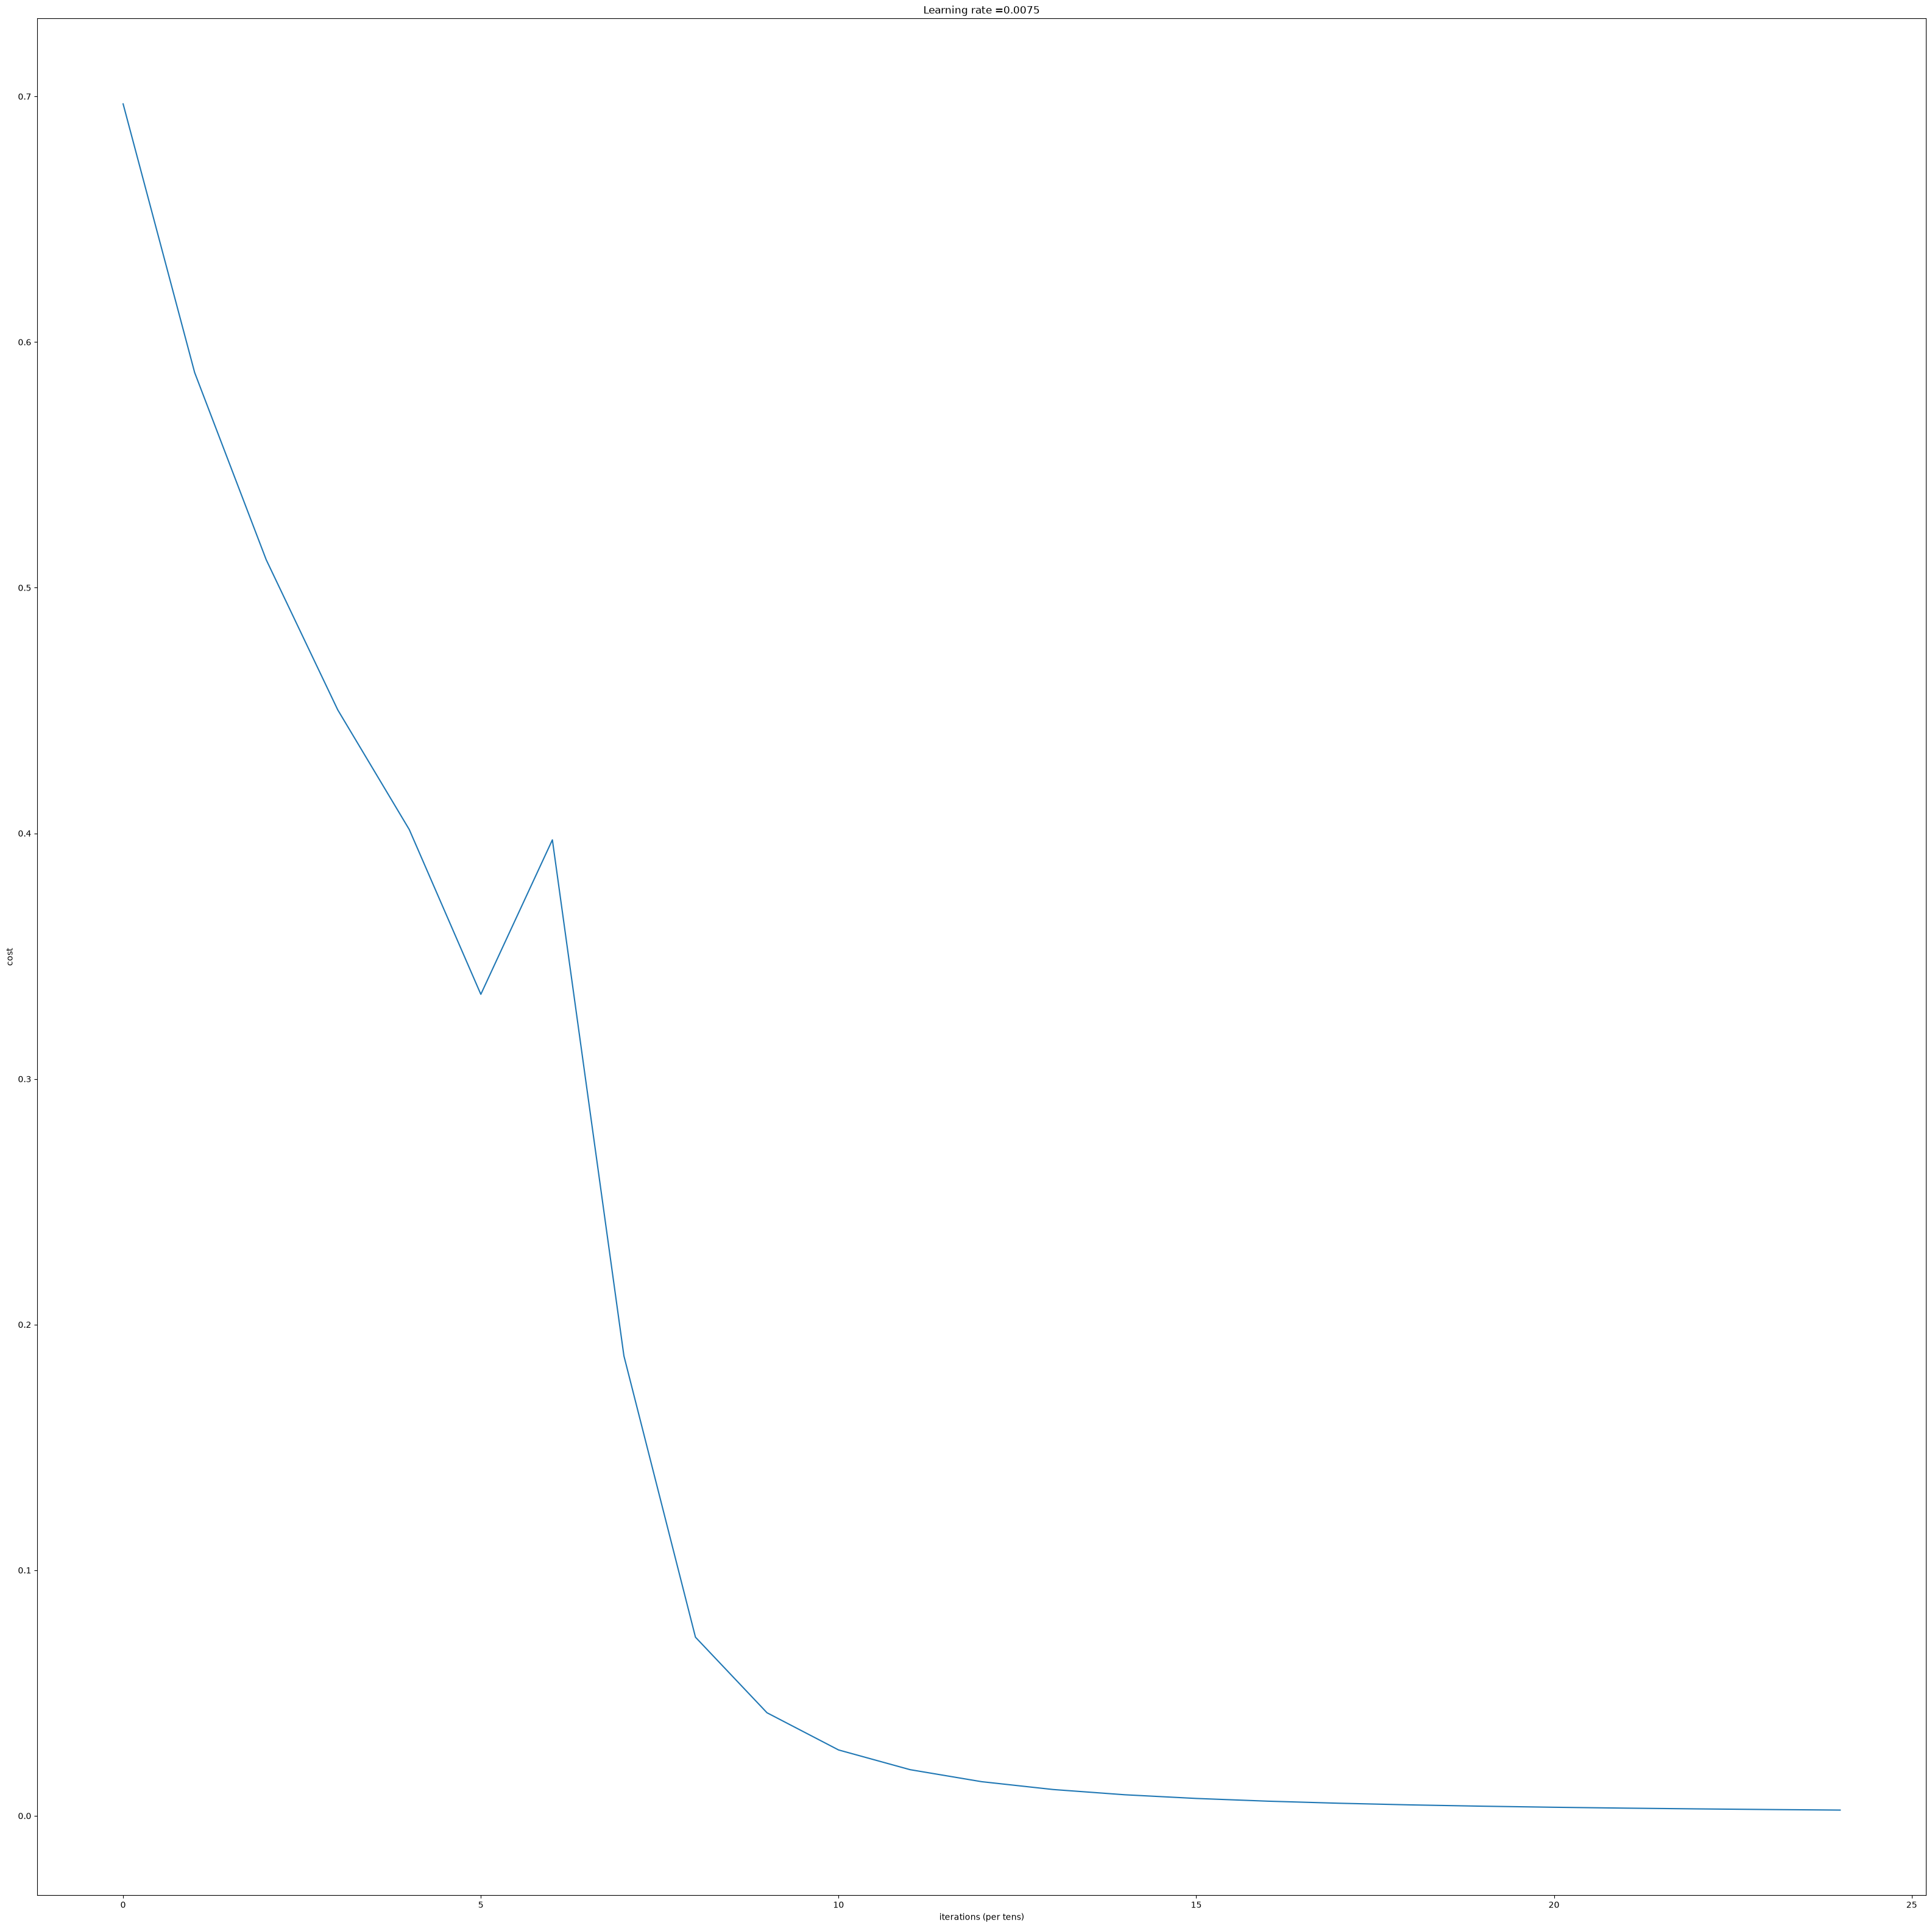

Accuracy: 0.9999999999999998
Accuracy: 0.74


In [53]:
results_summary = []

for exp in experiments:
    print(f"\n================ Running: {exp['name']} ================")
    
    np.random.seed(1)
    
    # Note: If your L_layer_model accepts an activation argument, pass it like this:
    # parameters = L_layer_model(train_x, train_y, exp["dims"], learning_rate=exp["lr"], num_iterations=exp["iters"], activation=exp["activation"], print_cost=False)
    
    # If your L_layer_model doesn't take an explicit activation parameter by default, 
    # it will use whatever default is hardcoded inside dnn_app_utils (usually ReLU).
    parameters = L_layer_model(train_x, train_y, exp["dims"], learning_rate=exp["lr"], num_iterations=exp["iters"], print_cost=False)
    
    # Evaluate accuracies
    pred_train = predict(train_x, train_y, parameters)
    pred_test = predict(test_x, test_y, parameters)
    
    train_acc = np.mean(pred_train == train_y) * 100
    test_acc = np.mean(pred_test == test_y) * 100
    
    results_summary.append({
        "Config": exp["name"],
        "Activation": exp["activation"],
        "Layers Dimensions": str(exp["dims"]),
        "Learning Rate": exp["lr"],
        "Iterations": exp["iters"],
        "Train Accuracy (%)": f"{train_acc:.2f}%",
        "Test Accuracy (%)": f"{test_acc:.2f}%"
    })

| Configuration | Activation (Requested) | Layers Dimensions | Learning Rate ($\alpha$) | Iterations | Train Accuracy | Test Accuracy |
| --- | --- | --- | --- | --- | --- | --- |
| **1. Baseline** | `ReLU` | `[12288, 20, 7, 5, 1]` | `0.0075` | 2500 | 98.56% | **80.00%** |
| **2. Tanh Activation** | `Tanh` *(Defaulted to ReLU)* | `[12288, 20, 7, 5, 1]` | `0.0075` | 2500 | 98.56% | **80.00%** |
| **3. Wider Network** | `ReLU` | `[12288, 64, 32, 16, 1]` | `0.0075` | 2500 | 100.00% | **82.00%** |
| **4. Extended Iterations** | `ReLU` | `[12288, 20, 7, 5, 1]` | `0.0075` | 5000 | 99.04% | **78.00%** |
| **5. Deeper Network** | `ReLU` | `[12288, 30, 20, 10, 5, 1]` | `0.0075` | 2500 | 100.00% | **74.00%** |